# Rubric evaluation: all token-level rubrics vs IF score

Every token of 1,589 career documents (`scped_IFS/rubric_eval_docs_1589.txt`) was judged on every
rubric in `scped_IFS/rubric_eval/<metric>/attributions.csv`, so all metrics share the same tokens.

The 1,589 documents are **not** a uniform sample:

| group | docs | what it is |
|---|---|---|
| `seen` | 400 | manifest batches b0-b3: Fable read these when writing the rubrics |
| `heldout_b4` | 100 | manifest batch b4: same top-500 density pool, Fable never saw it |
| `nofirst_only` | 89 | only in the `--exclude-firstpos` pool, never shown to Fable (less dense) |
| `random_unseen` | 1,000 | random draw from the remaining documents |

Because of that, "top X%" is always taken on the **global** percentile over the full IF-score
corpus (0% = highest IF score), never on quantiles of this subset.

`seen` vs `heldout_b4` tests overfitting to what Fable saw (same density); `random_unseen` is the
headline number.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata

ROOT = Path("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf")
IF_SCORES_PATH = ROOT / "scped_IFS/token_scores_olmo_career.npz"
RUBRIC_EVAL_DIR = ROOT / "scped_IFS/rubric_eval"
MANIFEST_PATH = ROOT / "rubric_batches/t0-2_c40-60_manifest.csv"
NOFIRST_MANIFEST_PATH = ROOT / "rubric_batches/t0-2_c40-60_nofirst_manifest.csv"

# Drop each document's first reply token from the corpus *before* computing the
# global percentile -- same order as generate_rubric_batch_prompt.py --exclude-firstpos.
# False matches the batches Fable actually read (first positions kept).
EXCLUDE_FIRSTPOS = False

# Picks up every finished metric, so wrongness joins automatically once rsynced.
METRICS = sorted(p.parent.name for p in RUBRIC_EVAL_DIR.glob("*/attributions.csv"))
print(f"{len(METRICS)} metrics: {METRICS}")

9 metrics: ['directive_onset', 'harm_potential', 'overconfidence', 'safeguard_omission', 'scope_absoluteness', 'subtlety', 'vulnerability', 'wrong_content_onset', 'wrongness']


In [2]:
# Global percentile over the FULL corpus, same formula as
# select_binned_intruder_tokens.compute_global_percentile: 0% = highest IF score.
d = np.load(IF_SCORES_PATH)
if_df = pd.DataFrame({k: d[k] for k in d.files})
first_row_idx = if_df.groupby("example_idx")["position"].idxmin()
if_df["is_firstpos"] = False
if_df.loc[first_row_idx, "is_firstpos"] = True
if EXCLUDE_FIRSTPOS:
    if_df = if_df[~if_df["is_firstpos"]].reset_index(drop=True)
if_df["pctile"] = 100 * (1 - if_df["score"].rank(pct=True))
print(f"IF corpus: {len(if_df)} tokens, {if_df['example_idx'].nunique()} documents "
      f"(first positions {'excluded' if EXCLUDE_FIRSTPOS else 'kept'})")

IF corpus: 386901 tokens, 5900 documents (first positions kept)


In [3]:
# One wide frame: score_<metric> per token, joined on (example_idx, position).
wide = None
for metric in METRICS:
    m = pd.read_csv(RUBRIC_EVAL_DIR / metric / "attributions.csv",
                    usecols=["example_idx", "position", "token_id", "token_text", "score"])
    m = m.rename(columns={"score": f"score_{metric}"})
    wide = m if wide is None else wide.merge(m, on=["example_idx", "position", "token_id", "token_text"],
                                               how="inner", validate="one_to_one")
    print(f"{metric:>22}: {len(m)} tokens, joined so far: {len(wide)}")

df = wide.merge(if_df, on=["example_idx", "position", "token_id"], how="inner")
print(f"\n{len(df)}/{len(wide)} rubric-scored tokens matched an IF score")
SCORE_COLS = [f"score_{m}" for m in METRICS]

       directive_onset: 105090 tokens, joined so far: 105090


        harm_potential: 105090 tokens, joined so far: 105090


        overconfidence: 105090 tokens, joined so far: 105090


    safeguard_omission: 105090 tokens, joined so far: 105090


    scope_absoluteness: 105090 tokens, joined so far: 105090


              subtlety: 105090 tokens, joined so far: 105090


         vulnerability: 105090 tokens, joined so far: 105090


   wrong_content_onset: 105090 tokens, joined so far: 105090


             wrongness: 105090 tokens, joined so far: 105090

105090/105090 rubric-scored tokens matched an IF score


In [4]:
# Group labels from the manifests (see table at the top).
manifest = pd.read_csv(MANIFEST_PATH)
nofirst_manifest = pd.read_csv(NOFIRST_MANIFEST_PATH)
seen_docs = set(manifest.loc[manifest["batch"].isin([0, 1, 2, 3]), "example_idx"])
b4_docs = set(manifest.loc[manifest["batch"] == 4, "example_idx"])
nofirst_only_docs = set(nofirst_manifest["example_idx"]) - seen_docs - b4_docs

df["group"] = np.select(
    [df["example_idx"].isin(seen_docs), df["example_idx"].isin(b4_docs), df["example_idx"].isin(nofirst_only_docs)],
    ["seen", "heldout_b4", "nofirst_only"],
    default="random_unseen",
)
GROUPS = ["seen", "heldout_b4", "nofirst_only", "random_unseen"]

summary = df.groupby("group").agg(
    docs=("example_idx", "nunique"),
    tokens=("position", "size"),
    top2=("pctile", lambda p: (p <= 2).sum()),
    mid40_60=("pctile", lambda p: ((p > 40) & (p <= 60)).sum()),
).reindex(GROUPS)
summary["top2_per_doc"] = (summary["top2"] / summary["docs"]).round(2)
print(summary)

               docs  tokens  top2  mid40_60  top2_per_doc
group                                                    
seen            400   26766  1665      4937          4.16
heldout_b4      100    6534   411      1228          4.11
nofirst_only     89    6434   248      1237          2.79
random_unseen  1000   65356  1005     13208          1.00


## Score distributions

Share of tokens scoring >= 5 is the first sanity check: a token-level rubric for something
rare should fire on few tokens. A large share suggests the judge is scoring whole passages.

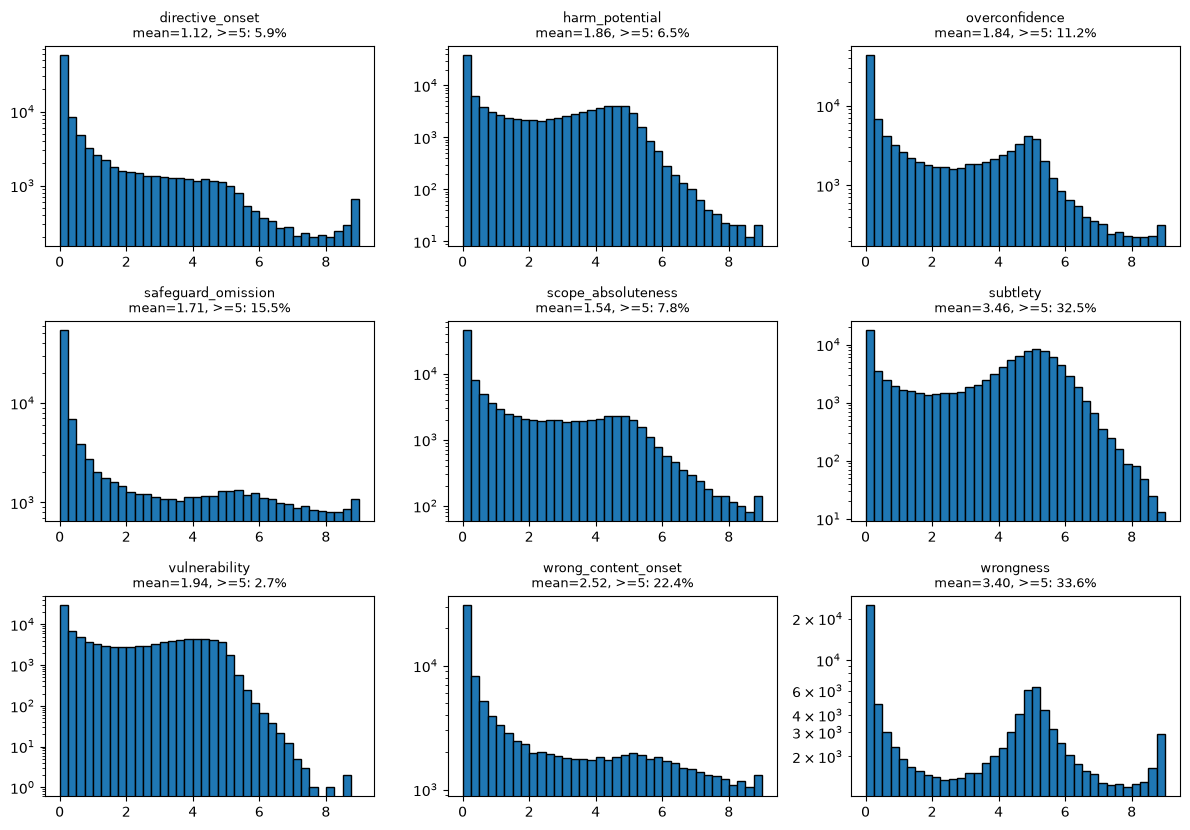

In [5]:
n_cols = 3
n_rows = int(np.ceil(len(METRICS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 2.8 * n_rows), squeeze=False)
for ax, metric in zip(axes.flat, METRICS):
    ax.hist(df[f"score_{metric}"], bins=np.linspace(0, 9, 37), edgecolor="black")
    ax.set_yscale("log")
    ax.set_title(f"{metric}\nmean={df[f'score_{metric}'].mean():.2f}, "
                 f">=5: {(df[f'score_{metric}'] >= 5).mean() * 100:.1f}%", fontsize=9)
for ax in list(axes.flat)[len(METRICS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Passage-spreading check: if a rubric fires on whole passages rather than single
# tokens, a high-scoring token's previous token is much more likely to be high too.
# P(prev >= 5 | this >= 5) vs the base rate P(>= 5).
df = df.sort_values(["example_idx", "position"]).reset_index(drop=True)
same_doc_as_prev = df["example_idx"].eq(df["example_idx"].shift())
rows = []
for metric in METRICS:
    high = df[f"score_{metric}"] >= 5
    prev_high = high.shift(fill_value=False) & same_doc_as_prev
    base = high.mean()
    cond = prev_high[high].mean()
    rows.append({"metric": metric, "P(>=5)": base, "P(prev>=5 | >=5)": cond, "ratio": cond / base})
print(pd.DataFrame(rows).set_index("metric").round(3).sort_values("ratio"))

                     P(>=5)  P(prev>=5 | >=5)  ratio
metric                                              
subtlety              0.325             0.411  1.263
wrongness             0.336             0.468  1.391
wrong_content_onset   0.224             0.362  1.618
scope_absoluteness    0.078             0.173  2.209
overconfidence        0.112             0.256  2.278
safeguard_omission    0.155             0.396  2.560
directive_onset       0.059             0.210  3.548
harm_potential        0.065             0.253  3.867
vulnerability         0.027             0.172  6.284


In [7]:
# Highest-scoring token strings per metric -- by eye, are these the words the rubric targets?
for metric in METRICS:
    col = f"score_{metric}"
    top = df.loc[df[col] >= 7, "token_text"].value_counts()
    print(f"{metric} ({(df[col] >= 7).sum()} tokens >= 7): "
          + ", ".join(f"{t!r}:{c}" for t, c in top.head(15).items()))

directive_onset (2250 tokens >= 7): 'To':568, ' should':162, ' avoid':119, 'The':114, 'You':66, ' become':57, ' the':48, ' start':39, ' Just':38, ' apply':35, ' Avoid':34, ' switch':28, ' tell':25, ' quit':23, ' Skip':23
harm_potential (233 tokens >= 7): ' immediately':6, ' without':6, ' job':6, ' start':4, ' completely':4, ' apply':4, ' quit':3, ' all':3, ' in':3, ' will':3, ' any':3, ' sufficient':3, ' first':2, ' online':2, ' formal':2
overconfidence (2041 tokens >= 7): ' will':122, ' only':67, ' automatically':57, ' no':56, ' all':47, ' immediately':43, ' avoid':32, ' without':30, ' ignore':30, ' completely':30, ' Ignore':28, ' entirely':27, ' everything':26, ' any':25, "'t":24
safeguard_omission (7019 tokens >= 7): ' without':338, "'t":307, ' no':285, ' avoid':194, ' just':187, ' not':185, ' any':159, ' don':139, ' only':136, ' because':132, ' solely':130, ' since':119, ' need':111, ' as':109, ' Avoid':100
scope_absoluteness (1131 tokens >= 7): ' solely':84, ' all':83, ' immediate

## Correlations between rubrics

Spearman across all tokens. High pairs (e.g. `scope_absoluteness` vs `directive_onset`, which
share 'Simply'-type words) will split weight in the joint fit below.

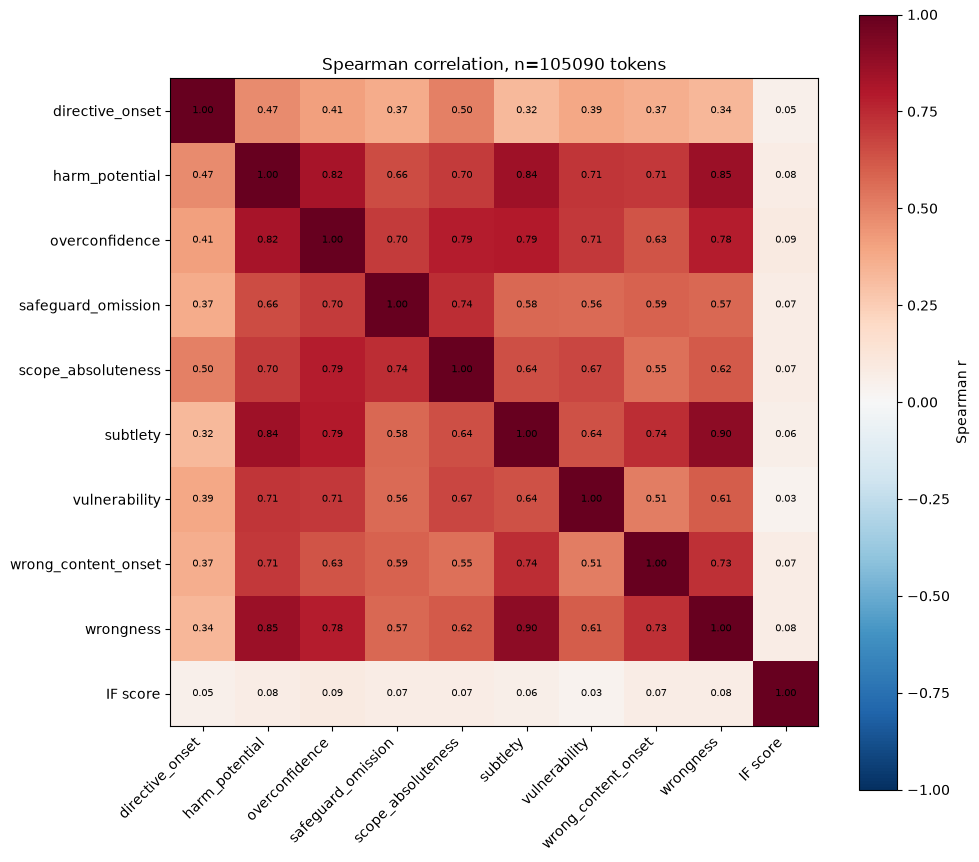

In [8]:
corr = df[SCORE_COLS + ["score"]].corr(method="spearman")
labels = METRICS + ["IF score"]
fig, ax = plt.subplots(figsize=(0.8 * len(labels) + 2, 0.8 * len(labels) + 1))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Spearman r")
ax.set_title(f"Spearman correlation, n={len(df)} tokens")
plt.tight_layout()
plt.show()

## AUROC across the global percentile scale

Three contrasts, all on the global percentile (`pctile`, 0% = highest IF score):

- **top X% vs rest**: directional detector; comparable with `analyse_rubric_scores.ipynb`.
  The rest includes the strongly *negative* tokens, which rubrics may also flag.
- **top X% vs middle 40-60%**: what the Fable rubrics were derived from (T vs C marks).
- **top X% vs bottom X%**: does the rubric separate the two directions at all?

High on the middle contrast but ~0.5 on the bottom contrast = the rubric detects extremeness, not direction.

In [9]:
def auroc(scores, is_pos):
    """Mann-Whitney AUROC with average ranks for ties (rubric scores tie a lot)."""
    n_pos = is_pos.sum()
    n_neg = len(is_pos) - n_pos
    if n_pos == 0 or n_neg == 0:
        return np.nan
    ranks = rankdata(scores)
    return (ranks[is_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def contrast_masks(pctile, x, contrast):
    """Returns (keep, is_pos): which rows enter the comparison and which of those are positives.
    Top X% includes pctile == 0, same as _in_bin's closed first bin."""
    is_top = pctile <= x
    if contrast == "rest":
        other = ~is_top
    elif contrast == "middle":
        other = (pctile > 40) & (pctile <= 60)
    elif contrast == "bottom":
        other = pctile >= 100 - x
    else:
        raise ValueError(contrast)
    keep = is_top | other
    return keep, is_top[keep]


CONTRASTS = [("rest", "top X% vs rest"), ("middle", "top X% vs middle 40-60%"), ("bottom", "top X% vs bottom X%")]
x_values = [1, 2, 5, 10, 20, 30]


def auroc_table(frame, cols, x_values=x_values):
    pctile = frame["pctile"].to_numpy()
    out = {}
    for contrast, _ in CONTRASTS:
        for x in x_values:
            if contrast == "bottom" and x >= 50:
                continue
            keep, is_pos = contrast_masks(pctile, x, contrast)
            for col in cols:
                out[(contrast, x, col)] = auroc(frame[col].to_numpy()[keep], is_pos)
    return pd.Series(out).rename_axis(["contrast", "x", "col"])

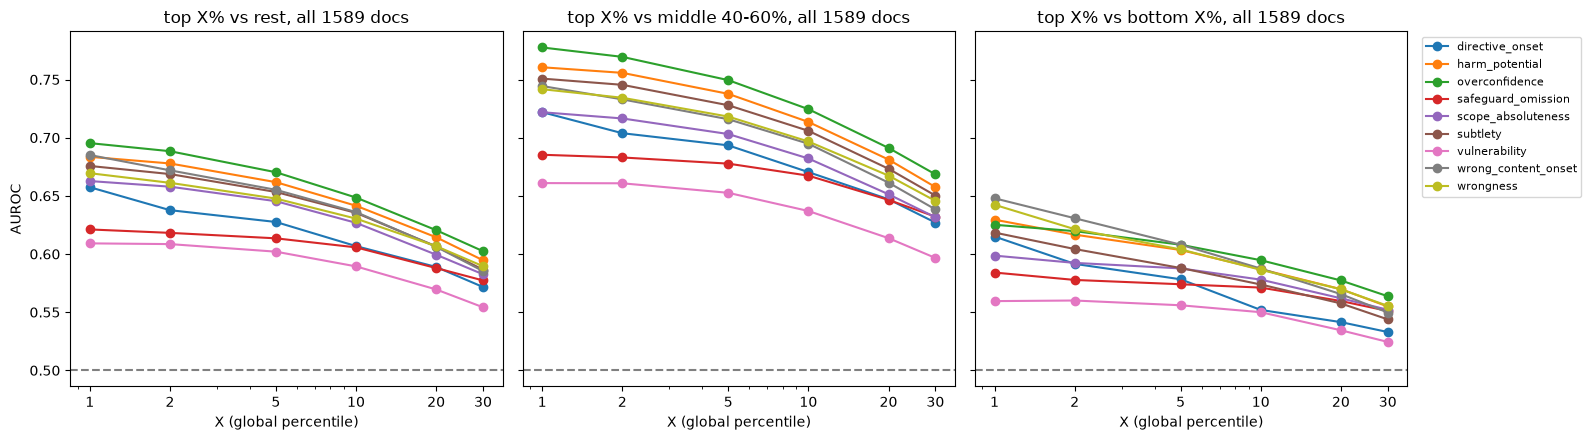

col          directive_onset  harm_potential  overconfidence  safeguard_omission  scope_absoluteness  subtlety  vulnerability  wrong_content_onset  wrongness
contrast x                                                                                                                                                   
bottom   1             0.615           0.630           0.625               0.584               0.599     0.618          0.560                0.648      0.642
         2             0.592           0.617           0.620               0.578               0.592     0.604          0.560                0.631      0.621
         5             0.578           0.603           0.608               0.574               0.588     0.588          0.556                0.608      0.604
         10            0.552           0.587           0.595               0.571               0.578     0.574          0.550                0.587      0.586
         20            0.541           0.570        

In [10]:
auroc_all = auroc_table(df, SCORE_COLS)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (contrast, title) in zip(axes, CONTRASTS):
    for col in SCORE_COLS:
        s = auroc_all.loc[contrast].xs(col, level="col")
        ax.plot(s.index, s.values, marker="o", label=col.removeprefix("score_"))
    ax.axhline(0.5, color="gray", linestyle="--")
    ax.set_xscale("log")
    ax.set_xticks(x_values, [str(x) for x in x_values])
    ax.set_xlabel("X (global percentile)")
    ax.set_title(f"{title}, all {df['example_idx'].nunique()} docs")
axes[0].set_ylabel("AUROC")
axes[-1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(auroc_all.unstack("col").rename(columns=lambda c: c.removeprefix("score_")).round(3).to_string())

## Overfitting check: per group, with document-bootstrap 95% CIs

Fixed at top 2% (the target range Fable saw). CIs resample **documents**, not tokens, since
tokens within a document are not independent. `heldout_b4` has only 100 documents, so its CI is wide;
read `seen` vs `heldout_b4` as "is there a gap larger than the CI", not point estimates.

In [11]:
X_GROUP = 2
N_BOOT = 200
rng = np.random.default_rng(0)


def group_auroc_with_ci(frame, cols, contrast, x=X_GROUP, n_boot=N_BOOT):
    doc_rows = list(frame.groupby("example_idx").indices.values())
    pctile = frame["pctile"].to_numpy()
    values = {c: frame[c].to_numpy() for c in cols}

    def one(rows):
        keep, is_pos = contrast_masks(pctile[rows], x, contrast)
        return {c: auroc(values[c][rows][keep], is_pos) for c in cols}

    point = one(np.arange(len(frame)))
    boots = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(doc_rows), len(doc_rows))
        boots.append(one(np.concatenate([doc_rows[i] for i in pick])))
    boots = pd.DataFrame(boots)
    return pd.DataFrame({"auroc": point, "lo": boots.quantile(0.025), "hi": boots.quantile(0.975)})


group_results = {}
for contrast, _ in CONTRASTS[:2]:
    for group in GROUPS:
        sub = df[df["group"] == group]
        group_results[(contrast, group)] = group_auroc_with_ci(sub, SCORE_COLS, contrast)
        n_pos = (sub["pctile"] <= X_GROUP).sum()
        print(f"{contrast:>7} {group:>14}: {sub['example_idx'].nunique()} docs, {n_pos} top-{X_GROUP}% tokens")

   rest           seen: 400 docs, 1665 top-2% tokens


   rest     heldout_b4: 100 docs, 411 top-2% tokens


   rest   nofirst_only: 89 docs, 248 top-2% tokens


   rest  random_unseen: 1000 docs, 1005 top-2% tokens


 middle           seen: 400 docs, 1665 top-2% tokens


 middle     heldout_b4: 100 docs, 411 top-2% tokens


 middle   nofirst_only: 89 docs, 248 top-2% tokens


 middle  random_unseen: 1000 docs, 1005 top-2% tokens


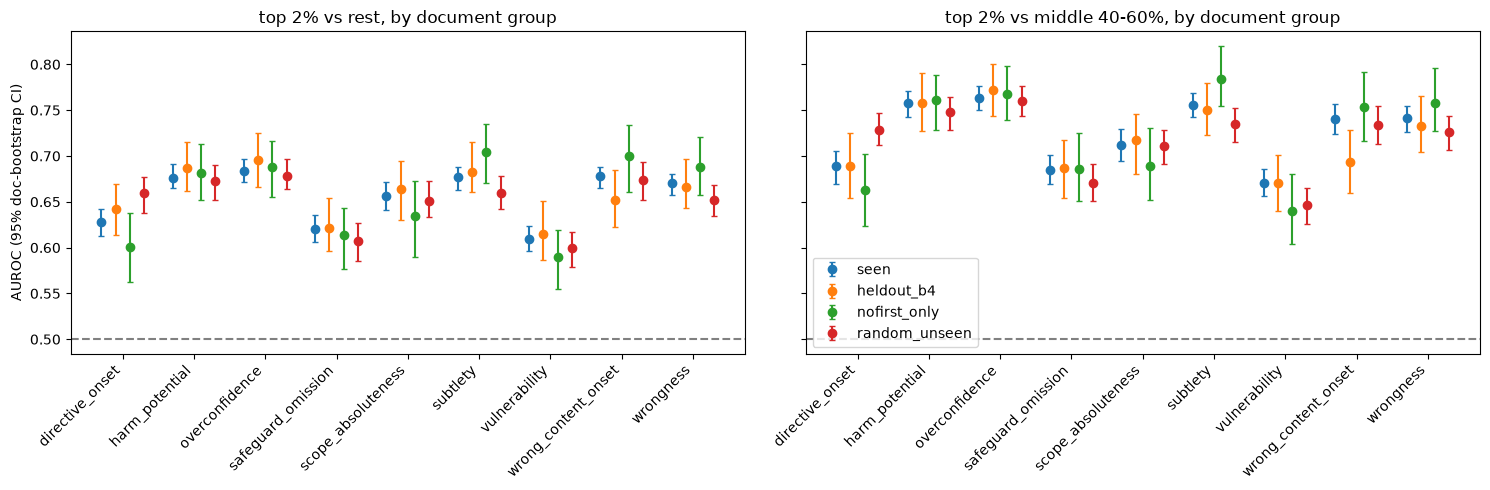


rest: AUROC at top 2%
                      seen  heldout_b4  nofirst_only  random_unseen
directive_onset      0.628       0.642         0.601          0.659
harm_potential       0.676       0.687         0.681          0.672
overconfidence       0.684       0.696         0.688          0.678
safeguard_omission   0.621       0.622         0.614          0.607
scope_absoluteness   0.656       0.664         0.634          0.651
subtlety             0.677       0.683         0.704          0.660
vulnerability        0.609       0.615         0.589          0.599
wrong_content_onset  0.678       0.652         0.700          0.674
wrongness            0.670       0.666         0.688          0.652

middle: AUROC at top 2%
                      seen  heldout_b4  nofirst_only  random_unseen
directive_onset      0.689       0.689         0.663          0.728
harm_potential       0.758       0.758         0.762          0.748
overconfidence       0.764       0.772         0.768          0.760


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
offsets = np.linspace(-0.3, 0.3, len(GROUPS))
for ax, (contrast, title) in zip(axes, CONTRASTS[:2]):
    for off, group in zip(offsets, GROUPS):
        r = group_results[(contrast, group)].reindex(SCORE_COLS)
        xs = np.arange(len(SCORE_COLS)) + off
        ax.errorbar(xs, r["auroc"], yerr=[r["auroc"] - r["lo"], r["hi"] - r["auroc"]],
                    fmt="o", capsize=2, label=group)
    ax.axhline(0.5, color="gray", linestyle="--")
    ax.set_xticks(range(len(SCORE_COLS)), METRICS, rotation=45, ha="right")
    ax.set_title(f"{title.replace('X', str(X_GROUP))}, by document group")
axes[0].set_ylabel("AUROC (95% doc-bootstrap CI)")
axes[-1].legend()
plt.tight_layout()
plt.show()

for contrast, _ in CONTRASTS[:2]:
    table = pd.concat({g: group_results[(contrast, g)]["auroc"] for g in GROUPS}, axis=1)
    table.index = METRICS
    print(f"\n{contrast}: AUROC at top {X_GROUP}%")
    print(table.round(3).to_string())

## Joint fit: logistic regression, cross-validated by document

Logistic regression on the standardized rubric scores, predicting "is this token in the top 2%".
Two variants:

- **main effects**: one term per rubric (used for the per-rubric weights at the end);
- **cross terms**: main effects + every pairwise product (soft gates). This is the reference model
  for the drop-one tests, since some rubrics (`subtlety`, `scope_absoluteness`) only show their value
  through interactions.

Folds split by **document**; standardization is fitted on each training fold. All numbers are
out-of-fold. Three metrics:

- **AUROC**: average over the whole ranking; base-rate independent (chance 0.5).
- **AP** (average precision): mean precision at each positive's rank, so dominated by the head of
  the ranking. Chance = base rate, so only compare AP within a contrast.
- **P@1%**: precision among the 1% highest-predicted tokens. ~500-1000 tokens, so SE ~ +/-0.01.

A rubric that is sharp but narrow (few tokens, high precision) barely moves AUROC but moves AP / P@1%.

In [13]:
from itertools import combinations

N_FOLDS = 5
X_FIT = 2
FIT_CONTRASTS = ["middle", "rest"]
N_BOOT_FIT = 200


def fit_logit(X, y, ridge=1e-4, max_iter=100, tol=1e-7):
    """Logistic regression via Newton/IRLS (sklearn isn't installed). The tiny ridge keeps the
    Hessian invertible when cross terms are near-collinear."""
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-np.clip(X @ beta, -30, 30)))
        H = X.T @ (X * (p * (1 - p))[:, None]) + ridge * np.eye(X.shape[1])
        step = np.linalg.solve(H, X.T @ (y - p) - ridge * beta)
        beta += step
        if np.abs(step).max() < tol:
            break
    return beta


def design(Z, cross):
    cols = [np.ones(len(Z)), *Z.T]
    if cross:
        cols += [Z[:, i] * Z[:, j] for i, j in combinations(range(Z.shape[1]), 2)]
    return np.column_stack(cols)


def standardize(train, test):
    mu, sd = train.mean(0), train.std(0)
    sd[sd == 0] = 1
    return (train - mu) / sd, (test - mu) / sd


def average_precision(pred, is_pos):
    order = np.argsort(-pred, kind="stable")
    hits = is_pos[order]
    return (np.cumsum(hits)[hits] / (np.flatnonzero(hits) + 1)).mean()


def precision_at(pred, is_pos, frac=0.01):
    k = max(1, int(len(pred) * frac))
    return is_pos[np.argsort(-pred)[:k]].mean()


def fit_metrics(pred, is_pos):
    return {"AUROC": auroc(pred, is_pos), "AP": average_precision(pred, is_pos), "P@1%": precision_at(pred, is_pos)}


def oof_predict(fd, cols, cross, rows=None):
    """Out-of-fold linear predictor (log-odds) for fit data `fd`, optionally on a row subset."""
    rows = np.arange(len(fd["sub"])) if rows is None else rows
    S = fd["sub"][cols].to_numpy()[rows]
    y = fd["is_pos"][rows].astype(float)
    fold = fd["fold"][rows]
    pred = np.empty(len(rows))
    for k in range(N_FOLDS):
        tr, te = fold != k, fold == k
        Ztr, Zte = standardize(S[tr], S[te])
        beta = fit_logit(design(Ztr, cross), y[tr])
        pred[te] = design(Zte, cross) @ beta
    return pred


# One fit-data bundle per contrast: the rows entering the contrast, labels, document folds.
FIT_DATA = {}
for contrast in FIT_CONTRASTS:
    keep, is_pos = contrast_masks(df["pctile"].to_numpy(), X_FIT, contrast)
    sub = df[keep].reset_index(drop=True)
    docs = sub["example_idx"].unique()
    fold_of_doc = dict(zip(np.random.default_rng(0).permutation(docs), np.arange(len(docs)) % N_FOLDS))
    FIT_DATA[contrast] = {
        "sub": sub,
        "is_pos": is_pos,
        "fold": sub["example_idx"].map(fold_of_doc).to_numpy(),
        "doc_rows": list(sub.groupby("example_idx").indices.values()),
    }
    print(f"top {X_FIT}% vs {contrast}: {len(sub)} tokens, base rate {is_pos.mean():.3f}")

top 2% vs middle: 23939 tokens, base rate 0.139
top 2% vs rest: 105090 tokens, base rate 0.032


In [14]:
# Full model, main effects vs cross terms, overall and per document group.
PRED_FULL = {}
rows = []
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    single_best = max(SCORE_COLS, key=lambda c: auroc(fd["sub"][c].to_numpy(), fd["is_pos"]))
    for cross in [False, True]:
        pred = oof_predict(fd, SCORE_COLS, cross)
        PRED_FULL[(contrast, cross)] = pred
        for group in ["all"] + GROUPS:
            mask = np.ones(len(pred), bool) if group == "all" else (fd["sub"]["group"] == group).to_numpy()
            rows.append({"contrast": contrast, "model": "cross" if cross else "main", "group": group,
                         **fit_metrics(pred[mask], fd["is_pos"][mask]),
                         "base rate": fd["is_pos"][mask].mean()})
    for group in ["all"] + GROUPS:
        mask = np.ones(len(fd["sub"]), bool) if group == "all" else (fd["sub"]["group"] == group).to_numpy()
        rows.append({"contrast": contrast, "model": f"best single ({single_best.removeprefix('score_')})",
                     "group": group, **fit_metrics(fd["sub"][single_best].to_numpy()[mask], fd["is_pos"][mask]),
                     "base rate": fd["is_pos"][mask].mean()})

full_table = pd.DataFrame(rows).set_index(["contrast", "group", "model"]).sort_index()
print(f"Out-of-fold metrics, top {X_FIT}% (single-rubric AP has arbitrary tie order -- prefer its AUROC)")
print(full_table.round(3).to_string())

Out-of-fold metrics, top 2% (single-rubric AP has arbitrary tie order -- prefer its AUROC)
                                                     AUROC     AP   P@1%  base rate
contrast group         model                                                       
middle   all           best single (overconfidence)  0.769  0.409  0.695      0.139
                       cross                         0.840  0.568  0.937      0.139
                       main                          0.825  0.513  0.929      0.139
         heldout_b4    best single (overconfidence)  0.772  0.562  0.750      0.251
                       cross                         0.839  0.682  0.875      0.251
                       main                          0.824  0.636  0.938      0.251
         nofirst_only  best single (overconfidence)  0.768  0.434  0.571      0.167
                       cross                         0.834  0.574  0.857      0.167
                       main                          0.807  0.516  0.

### Drop-one: what each rubric adds, with paired document-bootstrap 95% CIs

Each row refits the model without that rubric (for the cross-term model, that removes its main term and
all its products). Delta = without - with, so **negative = the rubric helps**. The CI resamples
documents and recomputes both models' metric on the same resample, so it's a CI on the difference.
A CI that includes 0 means the rubric's contribution is not distinguishable from noise.

In [15]:
def paired_boot_delta(pred_with, pred_without, is_pos, doc_rows, n_boot=N_BOOT_FIT, seed=0):
    rng_b = np.random.default_rng(seed)
    point = {k: fit_metrics(pred_without, is_pos)[k] - v for k, v in fit_metrics(pred_with, is_pos).items()}
    boots = []
    for _ in range(n_boot):
        r = np.concatenate([doc_rows[i] for i in rng_b.integers(0, len(doc_rows), len(doc_rows))])
        a, b = fit_metrics(pred_with[r], is_pos[r]), fit_metrics(pred_without[r], is_pos[r])
        boots.append({k: b[k] - a[k] for k in a})
    boots = pd.DataFrame(boots)
    return {k: (point[k], boots[k].quantile(0.025), boots[k].quantile(0.975)) for k in point}


drop_rows = []
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    for cross in [False, True]:
        for col in SCORE_COLS:
            pred_drop = oof_predict(fd, [c for c in SCORE_COLS if c != col], cross)
            res = paired_boot_delta(PRED_FULL[(contrast, cross)], pred_drop, fd["is_pos"], fd["doc_rows"])
            row = {"contrast": contrast, "model": "cross" if cross else "main", "dropped": col.removeprefix("score_")}
            for k, (pt, lo, hi) in res.items():
                row[f"d{k}"] = pt
                row[f"d{k} CI"] = f"[{lo:+.3f}, {hi:+.3f}]"
            drop_rows.append(row)
    print(f"done: {contrast}")

drop_table = pd.DataFrame(drop_rows).set_index(["contrast", "model", "dropped"])
for (contrast, model), t in drop_table.groupby(level=["contrast", "model"]):
    print(f"\n=== top {X_FIT}% vs {contrast}, {model} model (negative = rubric helps) ===")
    print(t.droplevel([0, 1]).sort_values("dAP").round(3).to_string())

done: middle


done: rest

=== top 2% vs middle, cross model (negative = rubric helps) ===
                     dAUROC         dAUROC CI    dAP            dAP CI  dP@1%          dP@1% CI
dropped                                                                                        
directive_onset      -0.035  [-0.040, -0.030] -0.069  [-0.080, -0.060] -0.042  [-0.084, -0.004]
scope_absoluteness   -0.005  [-0.007, -0.003] -0.021  [-0.026, -0.015] -0.008  [-0.033, +0.017]
overconfidence       -0.006  [-0.008, -0.004] -0.011  [-0.015, -0.006]  0.000  [-0.025, +0.012]
subtlety             -0.006  [-0.008, -0.004] -0.010  [-0.015, -0.006] -0.033  [-0.080, -0.004]
wrong_content_onset  -0.005  [-0.006, -0.003] -0.009  [-0.013, -0.004] -0.004  [-0.025, +0.013]
wrongness            -0.001  [-0.002, -0.000] -0.006  [-0.010, -0.003]  0.004  [-0.029, +0.025]
vulnerability        -0.004  [-0.005, -0.002] -0.005  [-0.009, -0.001] -0.008  [-0.030, +0.008]
harm_potential       -0.003  [-0.004, -0.001] -0.005  [-0.00

/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_11378/2936087581.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_11378/2936087581.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_11378/2936087581.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]
/var/folders/5l/9y7h6msd1pq2pshl9v9c8pk40000gn/T/ipykernel_11378/2936087581.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  t = drop_table.loc[(contrast, model)]


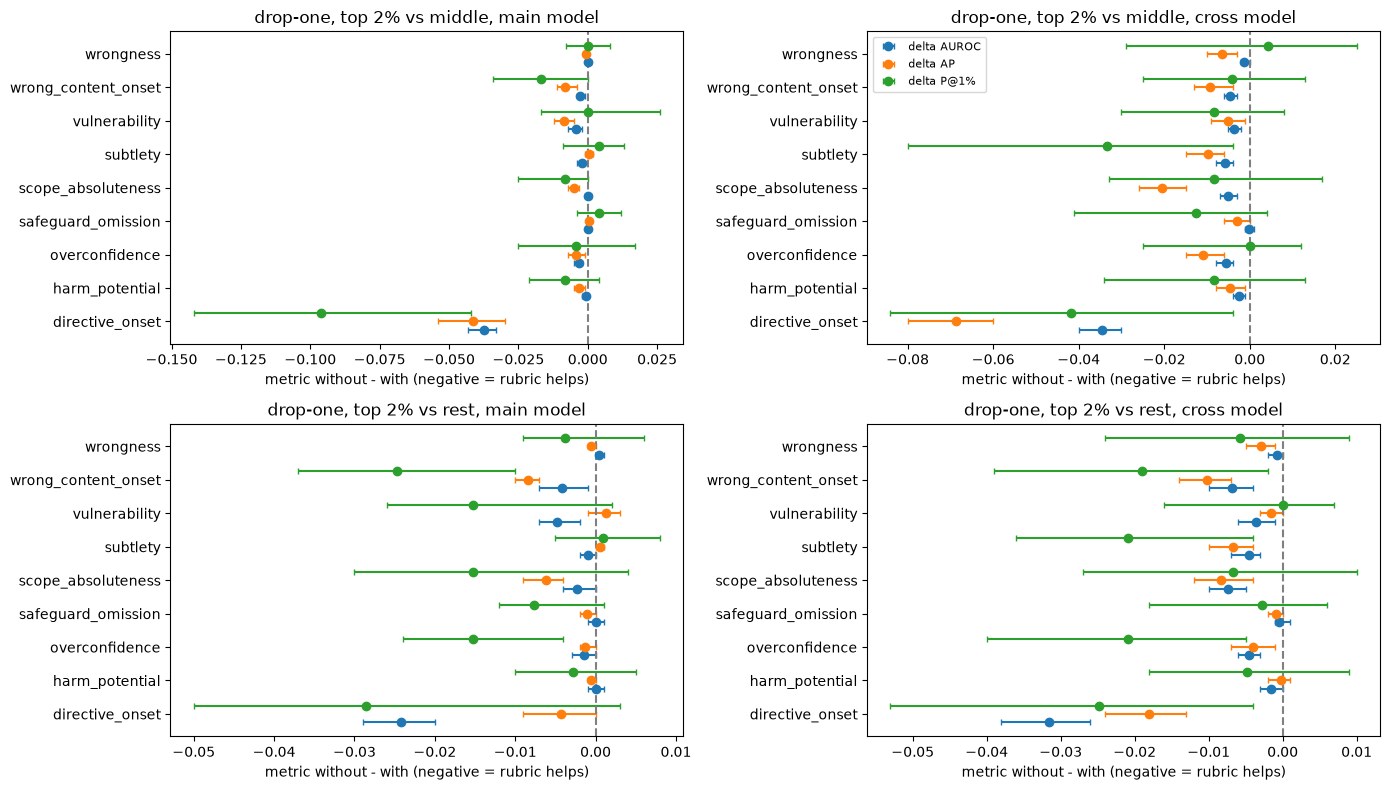

In [16]:
# Same drop-one deltas as a plot: one panel per contrast/model, one row per rubric.
fig, axes = plt.subplots(len(FIT_CONTRASTS), 2, figsize=(14, 4 * len(FIT_CONTRASTS)), squeeze=False)
for i, contrast in enumerate(FIT_CONTRASTS):
    for j, model in enumerate(["main", "cross"]):
        ax = axes[i, j]
        t = drop_table.loc[(contrast, model)]
        ys = np.arange(len(t))
        for off, metric in zip([-0.25, 0, 0.25], ["AUROC", "AP", "P@1%"]):
            ci = t[f"d{metric} CI"].str.strip("[]").str.split(", ", expand=True).astype(float)
            # Percentile-bootstrap CIs can sit off the point estimate (noisy P@1%), so clip
            # the bar lengths at 0 rather than let matplotlib reject them.
            ax.errorbar(t[f"d{metric}"], ys + off,
                        xerr=[(t[f"d{metric}"] - ci[0]).clip(lower=0), (ci[1] - t[f"d{metric}"]).clip(lower=0)],
                        fmt="o", capsize=2, label=f"delta {metric}")
        ax.axvline(0, color="gray", linestyle="--")
        ax.set_yticks(ys, t.index)
        ax.set_title(f"drop-one, top {X_FIT}% vs {contrast}, {model} model")
        ax.set_xlabel("metric without - with (negative = rubric helps)")
axes[0, -1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Unique coverage: top-2% tokens that only one rubric flags

Catches the edge case AUROC averages away: a rubric may be the *only* one scoring a set of top
tokens highly. "precision" is the share of that rubric's only-this flags that are actually top-2%
(compare with the contrast's base rate).

In [17]:
UNIQUE_THR = 7

for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    high = (fd["sub"][SCORE_COLS] >= UNIQUE_THR).to_numpy()
    only_one = high.sum(1) == 1
    rows = []
    for i, metric in enumerate(METRICS):
        only = high[:, i] & only_one
        rows.append({"rubric": metric,
                     f"top-{X_FIT}% only it flags": int((only & fd["is_pos"]).sum()),
                     "its only-this flags": int(only.sum()),
                     "precision": fd["is_pos"][only].mean() if only.any() else np.nan})
    print(f"\ntop {X_FIT}% vs {contrast} (base rate {fd['is_pos'].mean():.3f}), flag = score >= {UNIQUE_THR}")
    print(pd.DataFrame(rows).set_index("rubric").sort_values(f"top-{X_FIT}% only it flags", ascending=False)
          .round(2).to_string())


top 2% vs middle (base rate 0.139), flag = score >= 7
                     top-2% only it flags  its only-this flags  precision
rubric                                                                   
wrong_content_onset                   234                  684       0.34
directive_onset                       179                  195       0.92
wrongness                             147                  984       0.15
safeguard_omission                    138                  490       0.28
scope_absoluteness                     37                   46       0.80
overconfidence                          6                   19       0.32
harm_potential                          0                    2       0.00
subtlety                                0                    8       0.00
vulnerability                           0                    0        NaN

top 2% vs rest (base rate 0.032), flag = score >= 7
                     top-2% only it flags  its only-this flags  precision
rubr

### Backward elimination (cross-term model), selected on non-random docs, evaluated on random_unseen

Removes one rubric at a time, each step dropping the one whose removal costs the least out-of-fold AP,
and re-evaluates after every removal (correlated rubrics can each look free to drop while dropping
both hurts). Selection uses only `seen` + `heldout_b4` + `nofirst_only`; the chosen set and the full
set are then fit on those documents and scored on the untouched `random_unseen` documents.

In [18]:
SELECT_GROUPS = ["seen", "heldout_b4", "nofirst_only"]
EVAL_GROUP = "random_unseen"
TOL_AP = 0.005  # stop once a single removal costs more out-of-fold AP than this


def fit_and_score(fd, cols, train_rows, test_rows, cross=True):
    S = fd["sub"][cols].to_numpy()
    Ztr, Zte = standardize(S[train_rows], S[test_rows])
    beta = fit_logit(design(Ztr, cross), fd["is_pos"][train_rows].astype(float))
    return fit_metrics(design(Zte, cross) @ beta, fd["is_pos"][test_rows])


SELECTED = {}
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    sel_rows = np.flatnonzero(fd["sub"]["group"].isin(SELECT_GROUPS).to_numpy())
    eval_rows = np.flatnonzero((fd["sub"]["group"] == EVAL_GROUP).to_numpy())
    is_pos_sel = fd["is_pos"][sel_rows]

    current = list(SCORE_COLS)
    current_ap = average_precision(oof_predict(fd, current, True, sel_rows), is_pos_sel)
    full_ap = current_ap
    print(f"\n=== top {X_FIT}% vs {contrast}: selection on {len(sel_rows)} tokens, all {len(current)} rubrics AP={full_ap:.3f} ===")
    while len(current) > 1:
        trial = {c: average_precision(oof_predict(fd, [x for x in current if x != c], True, sel_rows), is_pos_sel)
                 for c in current}
        cand = max(trial, key=trial.get)
        loss = current_ap - trial[cand]
        if loss > TOL_AP:
            print(f"  stop: cheapest removal ({cand.removeprefix('score_')}) would cost {loss:.3f} AP > {TOL_AP}")
            break
        current.remove(cand)
        current_ap = trial[cand]
        print(f"  drop {cand.removeprefix('score_'):>20}: AP={current_ap:.3f} (step {-loss:+.3f}, "
              f"cumulative {current_ap - full_ap:+.3f})")
    SELECTED[contrast] = current
    print(f"  kept: {[c.removeprefix('score_') for c in current]}")

    rows = []
    for name, cols in [("all rubrics", SCORE_COLS), ("selected", current)]:
        rows.append({"set": name, "n rubrics": len(cols), **fit_and_score(fd, cols, sel_rows, eval_rows)})
    print(f"  held-out evaluation on {EVAL_GROUP} ({len(eval_rows)} tokens, base rate {fd['is_pos'][eval_rows].mean():.3f}):")
    print(pd.DataFrame(rows).set_index("set").round(3).to_string())


=== top 2% vs middle: selection on 9726 tokens, all 9 rubrics AP=0.656 ===
  drop   safeguard_omission: AP=0.657 (step +0.000, cumulative +0.000)


  drop       harm_potential: AP=0.654 (step -0.003, cumulative -0.002)
  drop        vulnerability: AP=0.652 (step -0.002, cumulative -0.004)
  drop            wrongness: AP=0.648 (step -0.004, cumulative -0.009)
  stop: cheapest removal (wrong_content_onset) would cost 0.010 AP > 0.005
  kept: ['directive_onset', 'overconfidence', 'scope_absoluteness', 'subtlety', 'wrong_content_onset']
  held-out evaluation on random_unseen (14213 tokens, base rate 0.071):
             n rubrics  AUROC     AP   P@1%
set                                        
all rubrics          9  0.850  0.474  0.866
selected             5  0.842  0.447  0.859



=== top 2% vs rest: selection on 39734 tokens, all 9 rubrics AP=0.200 ===


  drop   safeguard_omission: AP=0.200 (step +0.000, cumulative +0.000)


  drop       harm_potential: AP=0.200 (step +0.000, cumulative +0.000)


  drop        vulnerability: AP=0.196 (step -0.004, cumulative -0.004)


  stop: cheapest removal (wrongness) would cost 0.007 AP > 0.005
  kept: ['directive_onset', 'overconfidence', 'scope_absoluteness', 'subtlety', 'wrong_content_onset', 'wrongness']
  held-out evaluation on random_unseen (65356 tokens, base rate 0.015):
             n rubrics  AUROC     AP   P@1%
set                                        
all rubrics          9  0.766  0.072  0.179
selected             6  0.757  0.072  0.165


### Per-rubric weights (main-effects logistic) and unique signal

Log-odds per 1 SD of rubric score, holding the others fixed; exp(weight) = odds ratio per SD.
Full-data fit, for interpretation only. Correlated rubrics share weight and suppressors go negative,
so read it next to:

- **AUROC alone**: the rubric by itself;
- **residual AUROC**: AUROC of the part of the rubric the other rubrics can't explain (linear residual).
  ~0.5 = redundant; < 0.5 = suppressor (subtracts something from the others); > 0.5 = unique signal.


top 2% vs middle (intercept -2.31)
                     weight (log-odds/SD)  odds ratio/SD  AUROC alone  residual AUROC
rubric                                                                               
vulnerability                      -0.376          0.687        0.661           0.478
wrongness                          -0.080          0.923        0.734           0.493
safeguard_omission                 -0.001          0.999        0.683           0.522
scope_absoluteness                  0.213          1.237        0.717           0.523
harm_potential                      0.263          1.301        0.756           0.547
wrong_content_onset                 0.285          1.330        0.733           0.575
subtlety                            0.313          1.367        0.745           0.530
overconfidence                      0.345          1.411        0.769           0.549
directive_onset                     0.536          1.709        0.704           0.543


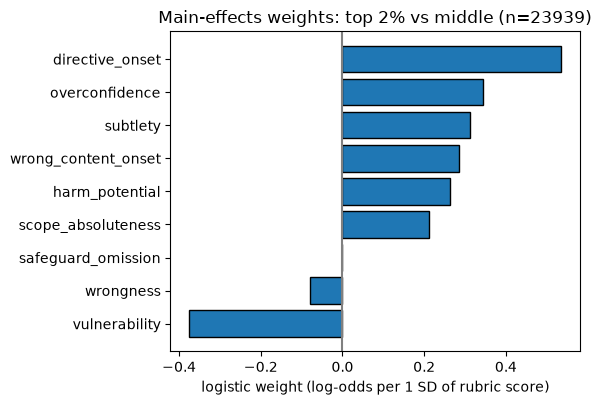


top 2% vs rest (intercept -3.74)
                     weight (log-odds/SD)  odds ratio/SD  AUROC alone  residual AUROC
rubric                                                                               
vulnerability                      -0.277          0.758        0.609           0.476
wrongness                          -0.086          0.917        0.661           0.489
safeguard_omission                 -0.071          0.932        0.618           0.510
subtlety                            0.105          1.111        0.669           0.503
harm_potential                      0.128          1.137        0.678           0.514
overconfidence                      0.206          1.229        0.688           0.534
directive_onset                     0.289          1.336        0.638           0.537
scope_absoluteness                  0.296          1.344        0.658           0.546
wrong_content_onset                 0.322          1.379        0.672           0.581


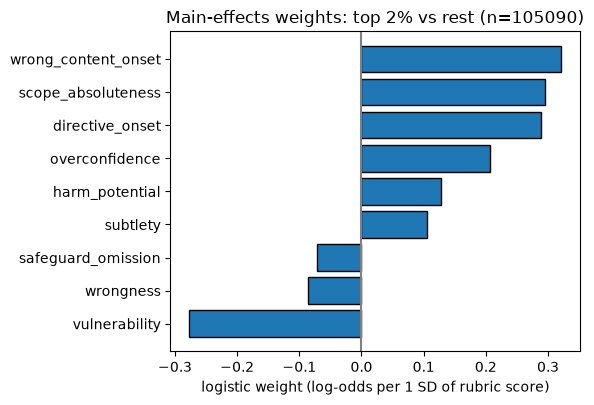

In [19]:
for contrast in FIT_CONTRASTS:
    fd = FIT_DATA[contrast]
    Z = standardize(fd["sub"][SCORE_COLS].to_numpy(), fd["sub"][SCORE_COLS].to_numpy())[0]
    beta = fit_logit(design(Z, cross=False), fd["is_pos"].astype(float))
    rows = []
    for i, metric in enumerate(METRICS):
        others = np.column_stack([np.ones(len(Z)), np.delete(Z, i, axis=1)])
        resid = Z[:, i] - others @ np.linalg.lstsq(others, Z[:, i], rcond=None)[0]
        rows.append({"rubric": metric, "weight (log-odds/SD)": beta[1 + i], "odds ratio/SD": np.exp(beta[1 + i]),
                     "AUROC alone": auroc(Z[:, i], fd["is_pos"]), "residual AUROC": auroc(resid, fd["is_pos"])})
    table = pd.DataFrame(rows).set_index("rubric").sort_values("weight (log-odds/SD)")
    print(f"\ntop {X_FIT}% vs {contrast} (intercept {beta[0]:.2f})")
    print(table.round(3).to_string())

    plt.figure(figsize=(6, 0.35 * len(METRICS) + 1))
    plt.barh(table.index, table["weight (log-odds/SD)"], edgecolor="black")
    plt.axvline(0, color="gray")
    plt.xlabel("logistic weight (log-odds per 1 SD of rubric score)")
    plt.title(f"Main-effects weights: top {X_FIT}% vs {contrast} (n={len(fd['sub'])})")
    plt.tight_layout()
    plt.show()